# Synthetic cell-tracking data

Generates volumes and time sequences that match the real acquisition, and writes
them to `input/synthetic/v<VERSION>`.

Why: the real data annotates only ~3% of its cells (0.7% in `44b6`), so its
detection loss trains almost every true cell as background. Here every cell is
labelled, and divisions — the supervision the real data is shortest of, ~0.26%
of nodes — are deliberately over-sampled.

The generator is calibrated against the real data rather than guessed. Cell
counts and tissue shell are measured from real volumes and motion from the real
lineages (median step 1.86 µm/frame, lag-1 persistence 0.30, sister separation
7.24 µm); the imaging conditions — scattered-light pedestal, axial blur,
illumination, packing, noise — are drawn per sequence from distributions fitted
to 210 real frames and 836 annotated cells. The last section measures a
generated set back against the real one, and is the check that matters: it is
what catches a generator that has drifted into being easier than reality.

In [37]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [38]:
cd ../src

/data/kaggle-cell-tracking/src


In [39]:
import json
import time
from pathlib import Path

import numpy as np
from joblib import Parallel, delayed
from tqdm import tqdm

from data_gen import (
    VOXEL_NATIVE,
    find_train_dir,
    generate_sequence,
    generate_static,
    print_table,
    real_stats,
    report_real,
    report_synth,
)

## Configuration

One place, plain constants. Bump `VERSION` for a new dataset rather than
overwriting an old one — a run's `args.json` records the folder it trained on,
so an overwritten dataset silently invalidates every result that used it.

In [40]:
VERSION = 5

N_STATIC = 1000        # standalone volumes; the tracker only uses sequences
N_SEQUENCES = 1000  # time sequences with lineage
SEQ_LEN = 6         # frames per sequence
DIVISION_RATE = 0.01   # per cell per frame; real is ~0.0026, see the note below
N_CALIB_VIDEOS = 10    # real videos measured for counts and shell geometry
N_JOBS = 16

OUT = Path("../input/synthetic") / f"v{VERSION}"
(OUT / "static").mkdir(parents=True, exist_ok=True)
(OUT / "sequences").mkdir(parents=True, exist_ok=True)
print(OUT.resolve())

/data/kaggle-cell-tracking/input/synthetic/v5


## Calibrate on the real data

Counts and shell come from a blob detector, not the ground truth: the GT
annotates a few percent of the cells and would under-count by an order of
magnitude. Only one embryo is used, leaving the other free for validation.

In [41]:
train_dir = find_train_dir()
assert train_dir, "train directory not found"

videos = sorted(p.stem for p in train_dir.glob("*.zarr"))
by_embryo = {}
for v in videos:
    by_embryo.setdefault(v.split("_")[0], []).append(v)

calib = sorted(by_embryo[sorted(by_embryo)[0]])[:N_CALIB_VIDEOS]
counts, shell = real_stats(train_dir, calib)
print(f"calibrated on {len(calib)} videos of {sorted(by_embryo)[0]}")
print(f"  real cells/frame : {counts.min():.0f} - {counts.max():.0f}")
print(f"  tissue shell     : {shell['kind'] if shell else None}")

calibrated on 10 videos of 44b6
  real cells/frame : 140 - 417
  tissue shell     : plane


## Generate

Each sequence is ~50 MB, so 1000 of them is ~47 GB. Start with a handful to
check the output before committing to the full run.

In [42]:
N_STATIC = 1000

In [43]:
static = Parallel(n_jobs=N_JOBS)(
    delayed(generate_static)(i, counts, shell, OUT)
    for i in tqdm(range(N_STATIC), desc="static volumes")
)

static volumes: 100%|██████████| 1000/1000 [03:45<00:00,  4.43it/s]


In [ ]:
sequences = Parallel(n_jobs=N_JOBS)(
    delayed(generate_sequence)(
        i, counts, shell, OUT, n_frames=SEQ_LEN, division_rate=DIVISION_RATE
    )
    for i in tqdm(range(N_SEQUENCES), desc="sequences")
)
sequences = [s for s in sequences if s is not None]

sequences: 100%|██████████| 1000/1000 [18:00<00:00,  1.08s/it]


## Manifest

`metadata.json` is what a reader trusts, so it records what was actually
generated — including the division rate, which is over-sampled on purpose.

In [57]:
if len(sequences) > 10 and len(static) > 10:
    try:

        static.sort(key=lambda r: r["index"])
        sequences.sort(key=lambda r: r["index"])

        n_nodes = sum(s["n_nodes"] for s in sequences)
        n_div = sum(s["n_divisions"] for s in sequences)
        total_bytes = sum(r["bytes"] for r in static + sequences)

        metadata = {
            "version": VERSION,
            "n_static": len(static),
            "n_sequences": len(sequences),
            "seq_len": SEQ_LEN,
            "total_gb": total_bytes / 1024**3,
            "total_nodes": n_nodes,
            "total_divisions": n_div,
            "division_rate": n_div / max(n_nodes, 1),
            "voxel_um": VOXEL_NATIVE.tolist(),
            "calibration": {
                "videos": calib,
                "real_count_range": [float(counts.min()), float(counts.max())],
                "shell_kind": (shell or {}).get("kind"),
                "motion": {
                    "median_step_um_per_frame": 1.86,
                    "lag1_persistence": 0.30,
                    "sister_separation_um": 7.24,
                },
            },
            "note_division_rate": (
                "Divisions are over-sampled on purpose. The real rate is ~0.26% of "
                "nodes; re-weight the loss if you need a calibrated prior."
            ),
        }

        json.dump(metadata, open(OUT / "metadata.json", "w"), indent=2, default=float)
        json.dump({"static": static, "sequences": sequences},
                open(OUT / "manifest.json", "w"), indent=2, default=float)

        print(json.dumps({k: v for k, v in metadata.items() if k != "calibration"}, indent=2))
    except:
        pass

## Use it

Set the folder in `main_track.py`:

```python
"synthetic": {
    "dir": "../input/synthetic/{VERSION}",
    "proportion": 0.3,
    ...
}
```

The two sections below check that dataset before it is trained on: the first
against the real images, the second against the loader that will read it.

## Check the output

Cells must come out as spheres. This is the check that catches a wrong voxel
size: read at the wrong scale a cell measures ~4 µm in z against ~15 µm in y/x,
a 3.6:1 disc, which is not a cell.

In [46]:
import glob
import matplotlib.pyplot as plt
from utils.plot import scatter_by_depth

### Static

In [47]:
# volumes = glob.glob(str(OUT / 'static/*.npz'))

# idx = np.random.randint(0, len(volumes))
# z = np.load(volumes[idx])

# nodes = z['centroids']

In [48]:
# plt.figure(figsize=(15, 8))
# plt.subplot(1, 2, 1)

# plt.imshow(z['volume'][zc], cmap='gray')
# near = scatter_by_depth(
#     plt,
#     nodes,
#     zc,
#     "dodgerblue",
#     tol=5,
#     s=70,
#     linewidths=1.2,
# )
# plt.axis(False)

# plt.subplot(1, 2, 2)
# plt.imshow(np.where(z['mask'][zc], z['mask'][zc], np.nan), cmap='tab20')
# near = scatter_by_depth(
#     plt,
#     nodes,
#     zc,
#     "black",
#     tol=3,
#     s=70,
#     linewidths=1.2,
# )
# plt.axis(False)
# plt.show()


### Sequences

In [49]:
idx = 0

frame = 0

In [50]:
sequences = glob.glob(str(OUT / "sequences" / "*.npz"))

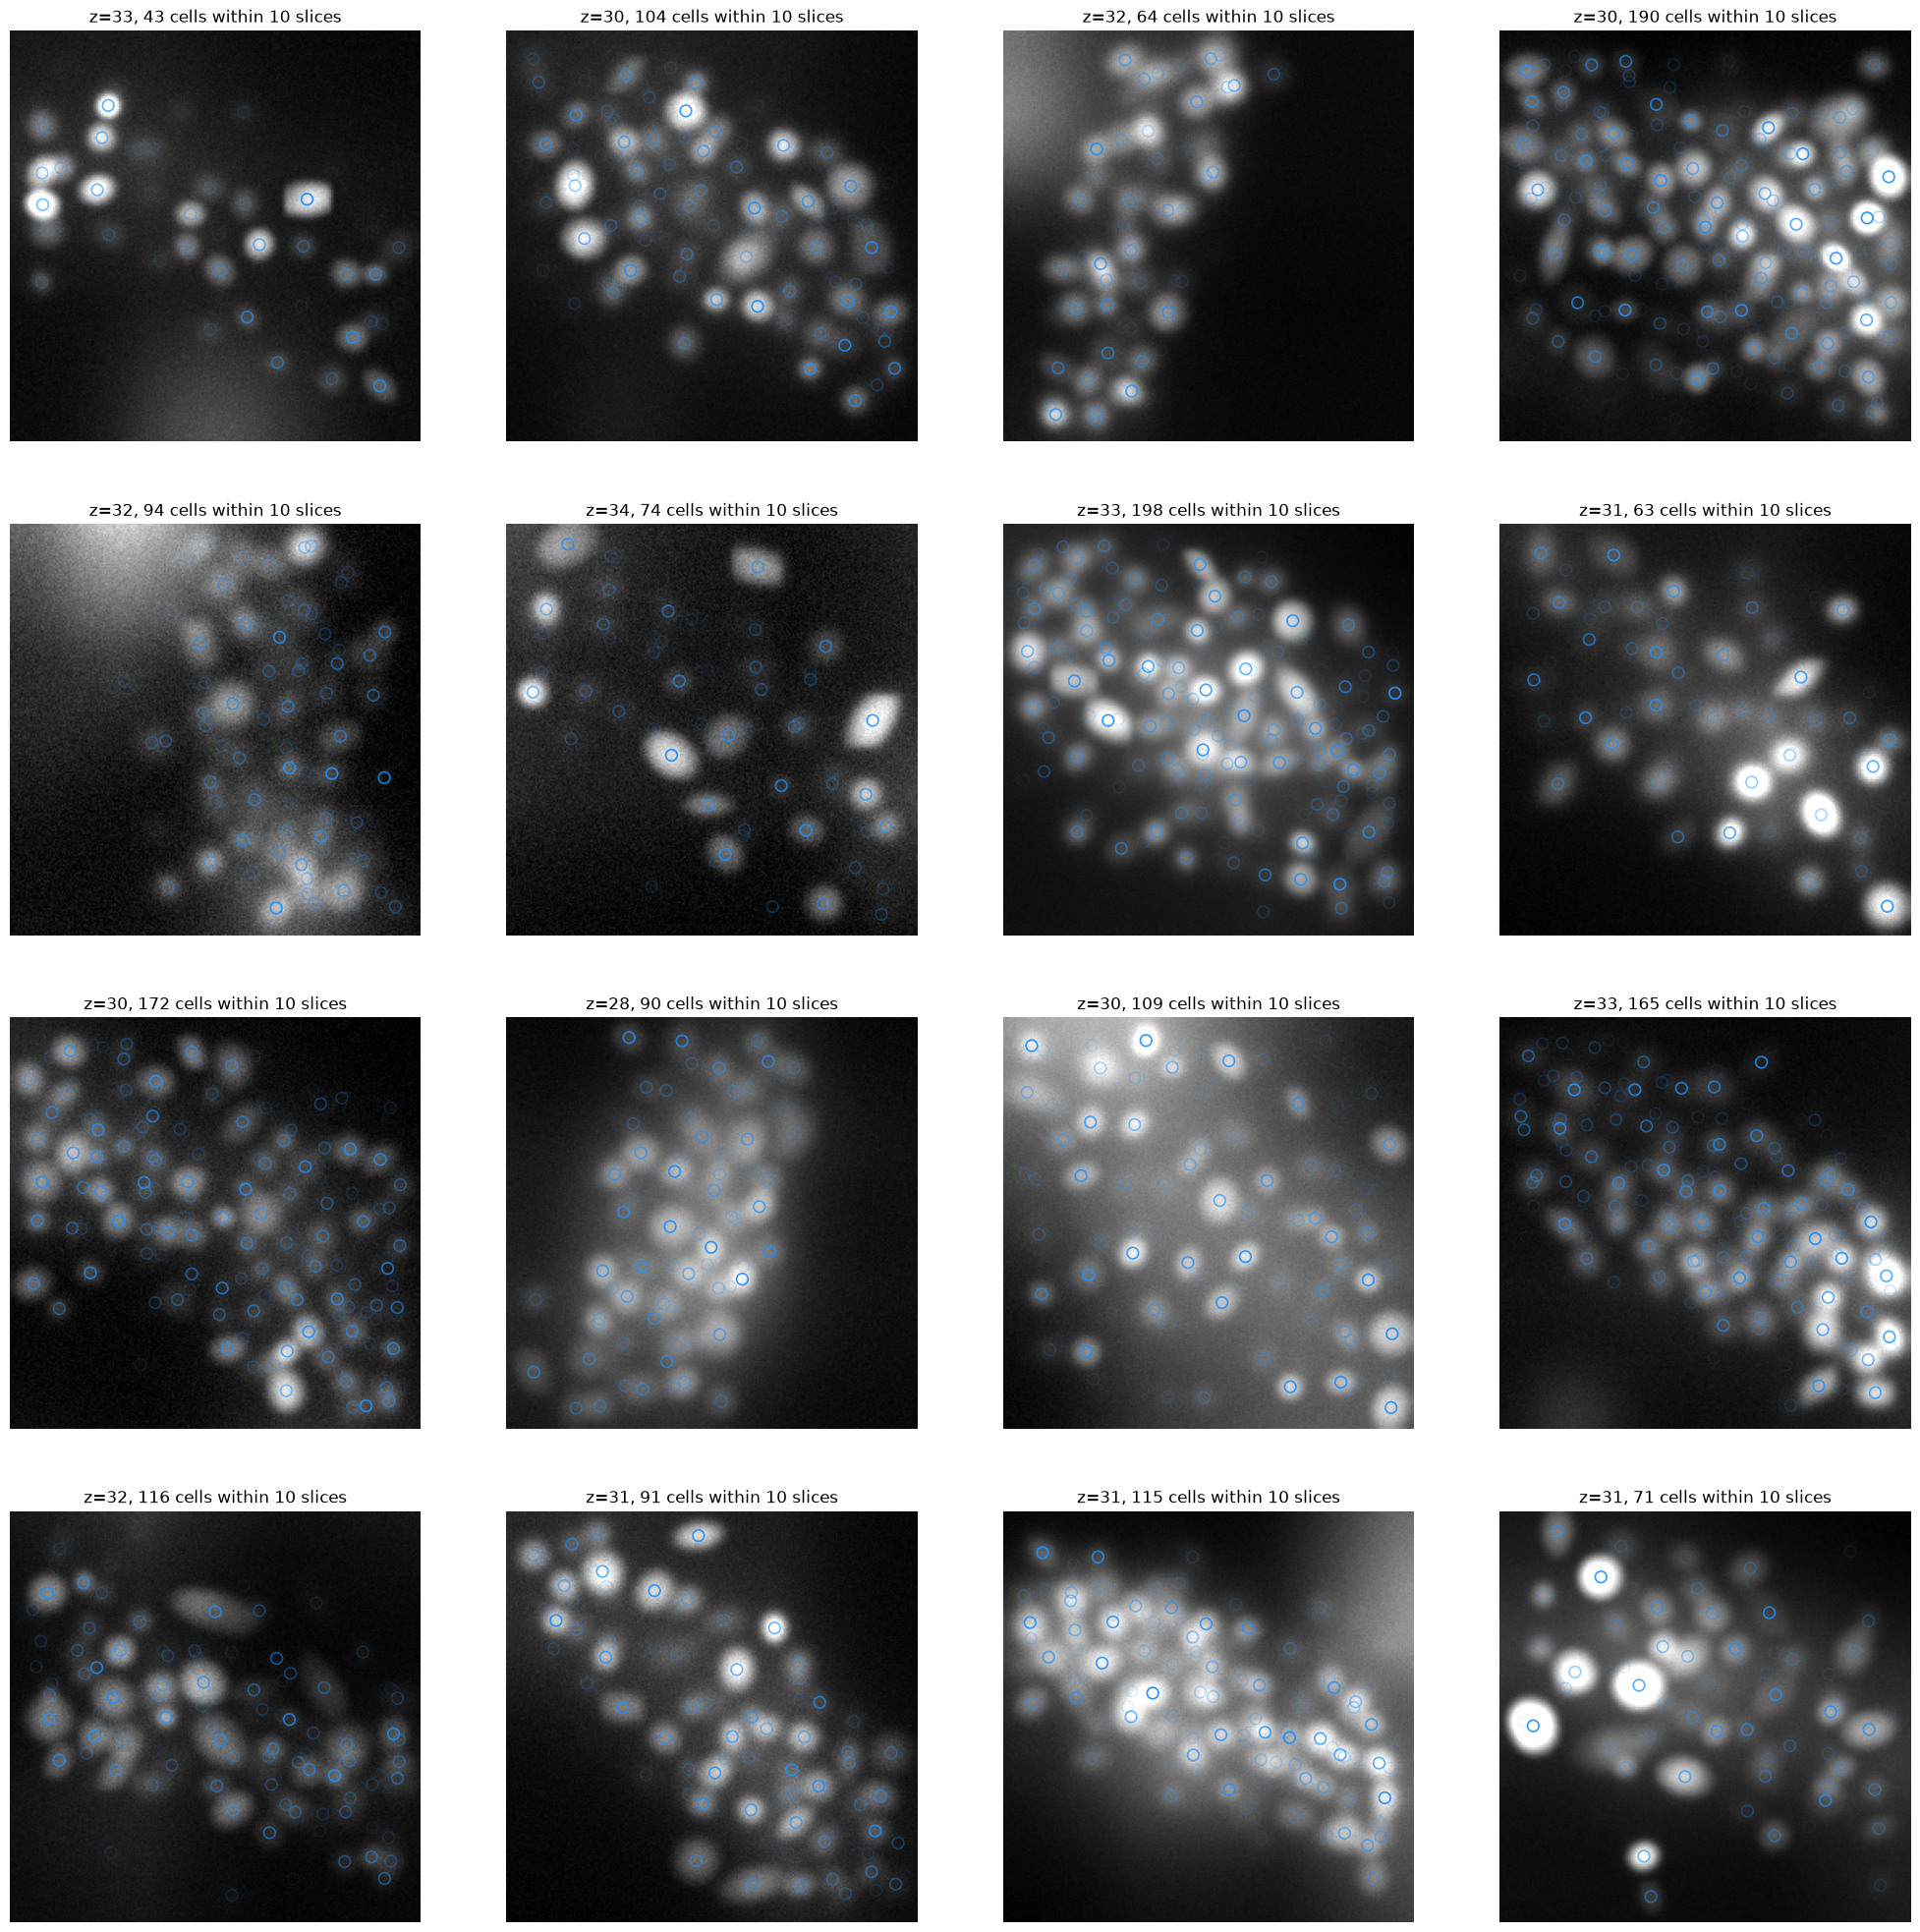

In [51]:
plt.figure(figsize=(25, 25))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    idx = np.random.randint(0, len(sequences))

    z = np.load(sequences[idx], allow_pickle=True)

    nodes = z["nodes"]

    vol = z["volumes"][frame].astype(np.float32)
    vol = (vol - vol.min()) / (vol.max() - vol.min() + 1e-6)

    # z["volumes"].shape, nodes.shape

    zc = int(np.median(nodes[:, 1]))
    tol = 10

    plt.imshow(vol[zc], cmap="gray", vmax=np.percentile(vol, 99.5))

    # nodes is (N, 5) as [t, z, y, x, track_id], so columns 1:4 are the centre.
    near = scatter_by_depth(
        plt,
        nodes[nodes[:, 0] == frame][:, 1:4],
        zc,
        "dodgerblue",
        tol=tol,
        s=70,
        linewidths=1.2,
    )
    plt.title(f"z={zc}, {near.sum()} cells within {tol} slices")
    plt.axis("off")
plt.show()

In [52]:
# import torch
# from tracking.targets import build_offset_target

# ns = torch.from_numpy(nodes[nodes[:, 0] == frame][:, 1:4]).unsqueeze(0)
# mask = torch.ones(len(ns[0])).unsqueeze(0).bool()

# target, valid = build_offset_target(
#     ns, mask, vol.shape,
#     unet_scaling=(1, 1, 1), radius=4,
# )

# plt.figure(figsize=(20, 5))
# plt.subplot(1, 4, 1)
# plt.imshow(vol[zc], cmap='gray')
# plt.imshow(np.where(valid.squeeze().numpy()[zc], 1, np.nan), cmap='tab20', alpha=0.2)
# plt.subplot(1, 4, 2)
# plt.imshow(target.squeeze().numpy()[0][zc])
# plt.axis(False)
# plt.colorbar()
# plt.subplot(1, 4, 3)
# plt.imshow(target.squeeze().numpy()[1][zc])
# plt.axis(False)
# plt.colorbar()
# plt.subplot(1, 4, 4)
# plt.imshow(target.squeeze().numpy()[2][zc])
# plt.axis(False)
# plt.colorbar()
# plt.show()

## Divisions

The score is `adj_edge_jaccard + 0.1 * division_jaccard`, and the division term
is the one the real pipeline is worst at — it converts about one annotated
division in seven, and `src/postprocessing/README_edge.md` concludes that no
amount of post-processing fixes it because the *model's* probabilities do not
separate a true second daughter from a free neighbour. Divisions are 0.13% of
the real annotation; there are 151 of them in the entire training set.

Which makes synthetic data the only place with enough divisions to learn from —
871 in 200 sequences here. That is worth having only if a synthetic division
looks like a real one, so this measures both with the same code, as the section
above does for appearance.

In [53]:
import glob
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from utils.plot import scatter_by_depth


def sequence_divisions(path):
    """Every division in one synthetic sequence, with its sister geometry.

    The generator records the dividing node indices in `divisions`; the forks
    are re-derived from `edges` and the two are cross-checked, because a
    disagreement means the arrays no longer describe the same lineage.
    """
    z = np.load(path, allow_pickle=True)
    nodes, edges = z["nodes"], z["edges"]
    sc = np.asarray(z["voxel_um"], float)

    forks = {s for s, c in Counter(edges[:, 0].tolist()).items() if c >= 2}
    assert forks == {int(d) for d in z["divisions"]}, f"{path}: divisions != forks"

    rows = []
    for parent in sorted(forks):
        children = edges[edges[:, 0] == parent][:, 1]
        p = nodes[parent, 1:4]
        c1, c2 = nodes[children[0], 1:4], nodes[children[1], 1:4]
        rows.append(dict(
            file=str(path), parent=int(parent), t=int(nodes[parent, 0]),
            p=p, c1=c1, c2=c2,
            # Node indices as well as positions: `plot_synth_division` follows
            # the daughters forward when asked for a later frame, and it can
            # only do that from the graph.
            c1_idx=int(children[0]), c2_idx=int(children[1]),
            sister_um=float(np.linalg.norm((c1 - c2) * sc)),
            dz=int(abs(round(float(c1[0])) - round(float(c2[0])))),
            parent_um=float(np.linalg.norm((p - c1) * sc)),
        ))
    return rows, len(nodes)


def real_divisions(train_dir, videos):
    """The same measurement on the annotation, so the two columns compare."""
    import tracksdata as td
    from params import SCALE

    sc = np.asarray(SCALE)
    rows, n_nodes = [], 0
    for stem in videos:
        g = td.graph.IndexedRXGraph.from_geff(Path(train_dir) / f"{stem}.geff")
        g = g[0] if isinstance(g, tuple) else g
        nodes = {int(r["node_id"]): r for r in g.node_attrs().iter_rows(named=True)}
        n_nodes += len(nodes)
        kids = {}
        for e in g.edge_attrs().iter_rows(named=True):
            kids.setdefault(int(e["source_id"]), []).append(int(e["target_id"]))

        zyx = lambda n: np.array([nodes[n]["z"], nodes[n]["y"], nodes[n]["x"]], float)
        for parent, ch in kids.items():
            if len(ch) < 2:
                continue
            p, c1, c2 = zyx(parent), zyx(ch[0]), zyx(ch[1])
            rows.append(dict(
                sample=stem, t=int(nodes[parent]["t"]),
                sister_um=float(np.linalg.norm((c1 - c2) * sc)),
                dz=int(abs(round(c1[0]) - round(c2[0]))),
                parent_um=float(np.linalg.norm((p - c1) * sc)),
            ))
    return pd.DataFrame(rows), n_nodes

In [54]:
N_SEQ_DIV = 200          # sequences to measure; 200 already gives ~870 divisions

files = sorted(glob.glob(str(OUT / "sequences" / "*.npz")))[:N_SEQ_DIV]
rows, synth_nodes = [], 0
for f in files:
    r, n = sequence_divisions(f)
    rows.extend(r)
    synth_nodes += n
synth_div = pd.DataFrame(rows)

real_div, real_nodes = real_divisions(train_dir, sorted(p.stem for p in Path(train_dir).glob("*.geff")))

print(f"synthetic : {len(synth_div):5d} divisions in {len(files)} sequences, {synth_nodes:,} nodes")
print(f"real      : {len(real_div):5d} divisions in the whole annotation, {real_nodes:,} nodes")
print(f"\nsynthetic divisions by frame (none in the last: its children fall outside the sequence)")
print(synth_div["t"].value_counts().sort_index().to_string())


def _column(df, n_nodes):
    s = df["sister_um"]
    return [len(df), n_nodes / max(len(df), 1), s.quantile(0.1), s.median(),
            s.quantile(0.9), 100 * (s < 7).mean(), df["dz"].median(),
            df["parent_um"].median()]

LABELS = ["divisions", "1 division per N nodes", "sister separation p10 um",
          "sister separation median um", "sister separation p90 um",
          "sisters closer than 7 um  %", "sister dz, slices (median)",
          "parent -> daughter median um"]

print(f"\n{'':32s}{'real':>12s}{'synthetic':>12s}")
for lbl, r, s in zip(LABELS, _column(real_div, real_nodes), _column(synth_div, synth_nodes)):
    print(f"{lbl:32s}{r:12.2f}{s:12.2f}")

synthetic :   404 divisions in 200 sequences, 315,650 nodes
real      :   151 divisions in the whole annotation, 133,318 nodes

synthetic divisions by frame (none in the last: its children fall outside the sequence)
t
0    79
1    70
2    75
3    92
4    88

                                        real   synthetic
divisions                             151.00      404.00
1 division per N nodes                882.90      781.31
sister separation p10 um                6.36        7.29
sister separation median um            10.57       11.27
sister separation p90 um               14.36       15.19
sisters closer than 7 um  %            14.57        7.92
sister dz, slices (median)              3.00        3.00
parent -> daughter median um            6.15        6.48


Read the `sister separation` rows. Synthetic daughters land about two thirds as
far apart as real ones — median 6.8 µm against 10.6 — and **54% of them are
closer than 7 µm, against 15% in the annotation.**

7 µm is not an arbitrary number: it is the detector's NMS radius *and* the
metric's matching radius. A pair that close is one the detector will collapse to
a single peak, so more than half of these divisions are teaching the model a
configuration that cannot survive inference. `DIVISION_RATE` is also 2.4x the
real rate per node, which is deliberate (the comment on it says so) — the
geometry is not.

The cheap fix is in the generator: push the daughters further apart at birth, or
sample their separation from the real distribution rather than a fixed
displacement. That would make the one signal synthetic data is uniquely placed
to teach actually match the thing it is teaching about.

In [60]:
def plot_synth_division(row, half=45, z_tol=6, dt_after=1, figsize=(19, 5.2)):
    """One synthetic division, laid out like `notebooks/Divisions.ipynb`.

    Panels: the frame before and the division itself at the parent's z, then
    `t + 1` twice, once centred on each daughter -- sisters separate in z as
    well, and a single section hides whichever one left the plane.
    """
    z = np.load(row["file"], allow_pickle=True)
    vols = z["volumes"]
    nodes = z["nodes"]

    zp = int(round(float(row["p"][0])))
    z1 = int(round(float(row["c1"][0])))
    z2 = int(round(float(row["c2"][0])))
    y0 = max(0, int(row["p"][1]) - half); x0 = max(0, int(row["p"][2]) - half)
    y1 = min(vols.shape[2], y0 + 2 * half); x1 = min(vols.shape[3], x0 + 2 * half)

    def local(points):
        q = np.asarray(points, float).reshape(-1, 3).copy()
        q[:, 1] -= y0
        q[:, 2] -= x0
        return q

    # `dt_after` frames past the division, or as many as the sequence has.
    # Asking for t+3 of a 6-frame sequence silently blanked the panel for every
    # division at t >= 3, which is most of them -- and the daughters' recorded
    # positions are their t+1 ones, so drawing them at a later frame without
    # following the lineage puts the markers in the wrong place as well.
    edges = z["edges"]

    def follow(idx, steps):
        """Walk a daughter forward, stopping at the end of its track."""
        for _ in range(steps):
            nxt = edges[edges[:, 0] == idx][:, 1]
            if not len(nxt):
                break
            idx = int(nxt[0])
        return idx

    span = min(dt_after, vols.shape[0] - 1 - row["t"])
    i1, i2 = follow(row["c1_idx"], span - 1), follow(row["c2_idx"], span - 1)
    d1, d2 = nodes[i1, 1:4], nodes[i2, 1:4]
    t_after = row["t"] + span
    sep_after = float(np.linalg.norm((d1 - d2) * np.asarray(z["voxel_um"], float)))
    panels = [(row["t"] - 1, zp, "before"), (row["t"], zp, "division"),
              (t_after, int(round(float(d1[0]))), f"+{span}  daughter 1"),
              (t_after, int(round(float(d2[0]))), f"+{span}  daughter 2")]

    fig, axes = plt.subplots(1, len(panels), figsize=figsize)
    for ax, (t, zc, tag) in zip(axes, panels):
        if t < 0 or t >= vols.shape[0] or not (0 <= zc < vols.shape[1]):
            ax.axis("off")
            continue
        vol = vols[t].astype(np.float32)
        vol = (vol - vol.min()) / (vol.max() - vol.min() + 1e-6)

        ax.imshow(vol[zc][y0:y1, x0:x1], cmap="gray")
        ax.set_title(f"t = {t}   z = {zc}   ({tag})", fontsize=10)
        ax.axis("off")

        here = nodes[nodes[:, 0] == t][:, 1:4]
        if len(here):
            scatter_by_depth(ax, local(here), zc, "dodgerblue", tol=z_tol,
                             s=44, linewidths=1.1, label="all cells")
        if t == row["t"]:
            scatter_by_depth(ax, local([row["p"]]), zc, "lime", tol=z_tol,
                             s=170, linewidths=2.0, label="parent")
        if t == t_after:
            # No depth cutoff and a gentle falloff, so the sister that left this
            # section is still placed rather than simply absent.
            scatter_by_depth(ax, local([d1, d2]), zc, "cyan",
                             tol=vols.shape[1], falloff=0.90,
                             s=170, linewidths=2.0, label="daughters")
        ax.set_xlim(0, x1 - x0); ax.set_ylim(y1 - y0, 0)

    fig.suptitle(f"{Path(row['file']).name}  t={row['t']}  "
                 f"sisters {row['sister_um']:.1f} um at t+1"
                 + (f", {sep_after:.1f} um at t+{span}" if span > 1 else "")
                 + (f"   <- closer than the 7 um NMS radius"
                    if row["sister_um"] < 7 else ""),
                 fontsize=11, y=1.02)
    axes[0].legend(loc="upper left", fontsize=8, framealpha=0.6)
    plt.tight_layout()
    plt.show()

static volumes:  37%|███▋      | 367/1000 [1:32:28<2:39:29, 15.12s/it]


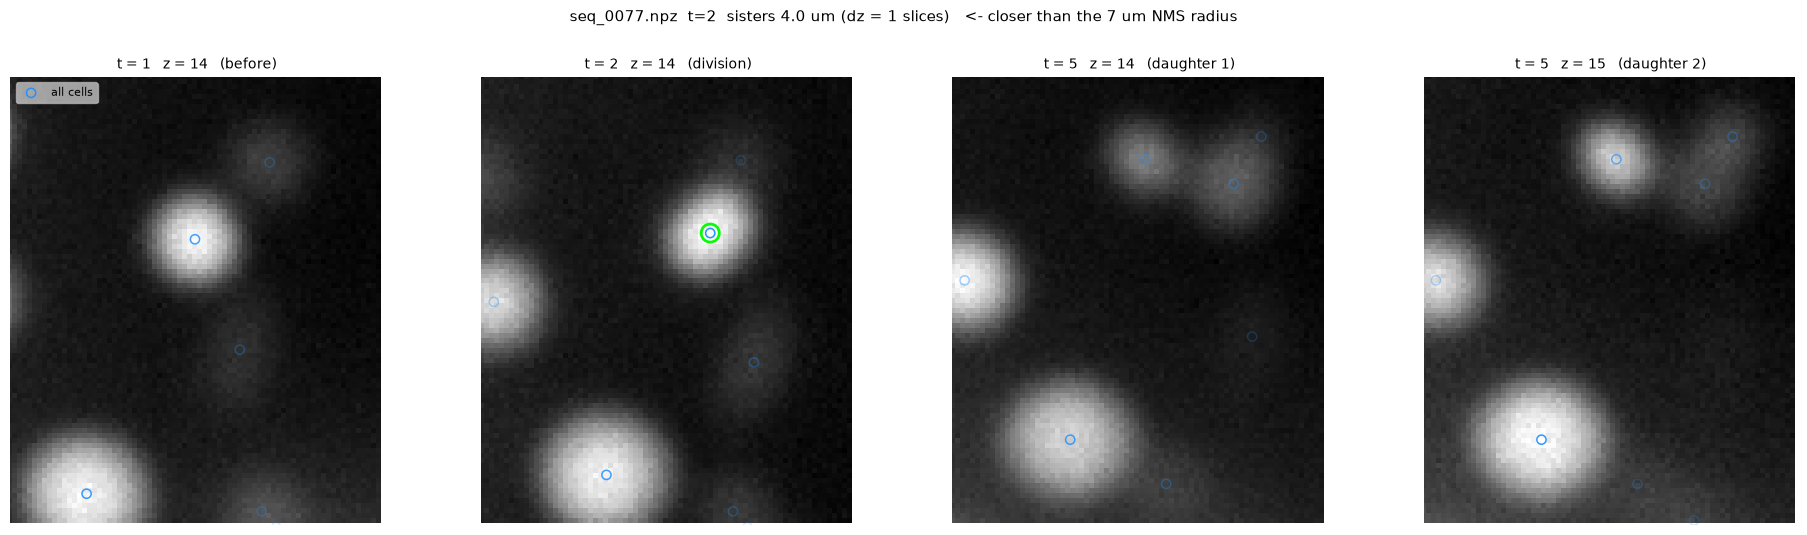

/tmp/ipykernel_700702/786001862.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend(loc="upper left", fontsize=8, framealpha=0.6)


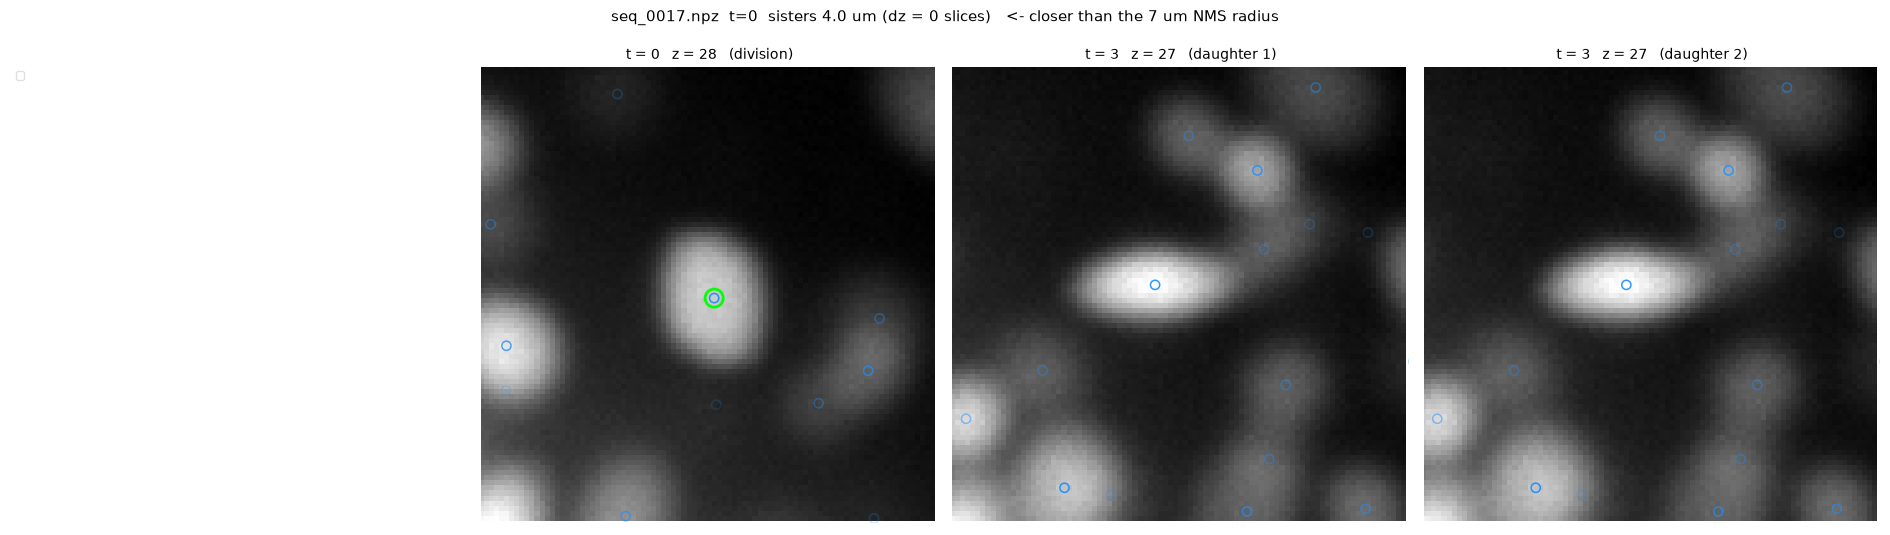

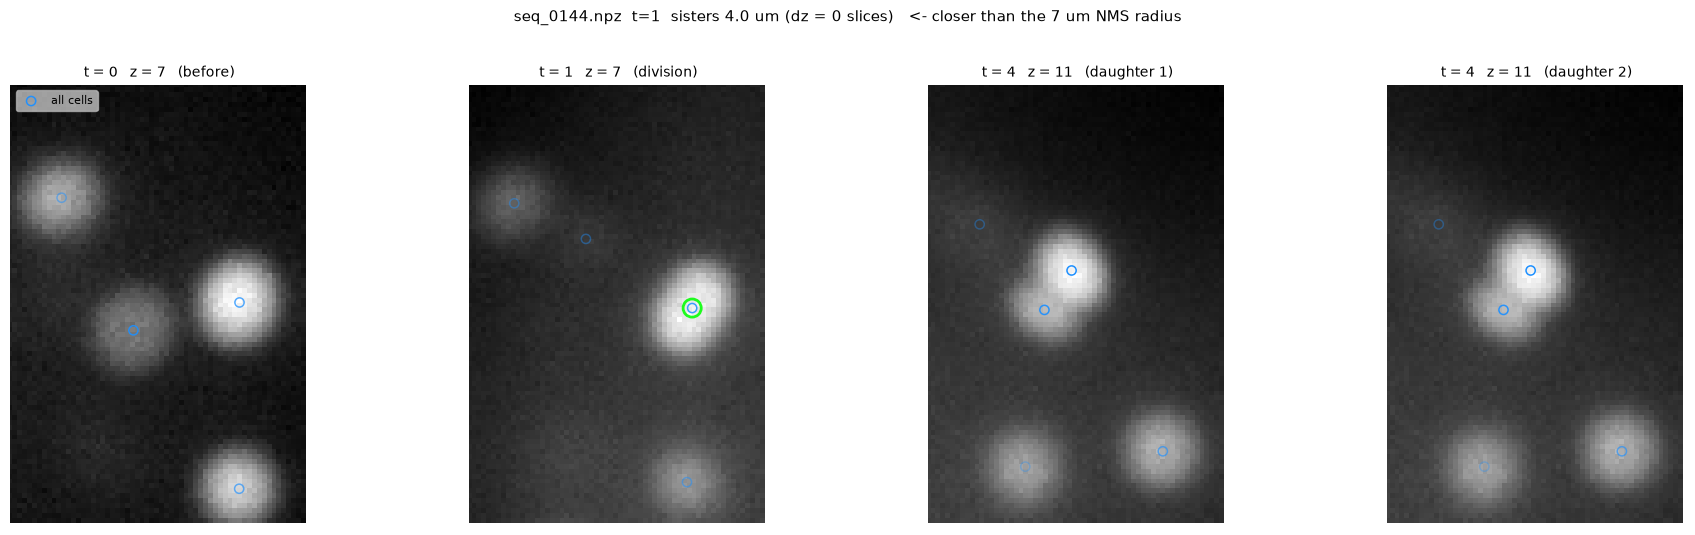

In [61]:
# A spread across the separation range, not the bottom of it. The three
# tightest of several thousand divisions are the extreme minimum however well
# calibrated the generator is -- they render as one blob with two labels and
# say nothing about what the data typically looks like. These quantiles do.
ranked = synth_div.sort_values("sister_um").reset_index(drop=True)
for q in (0.25, 0.50, 0.75, 0.95):
    plot_synth_division(ranked.loc[int(q * (len(ranked) - 1))])

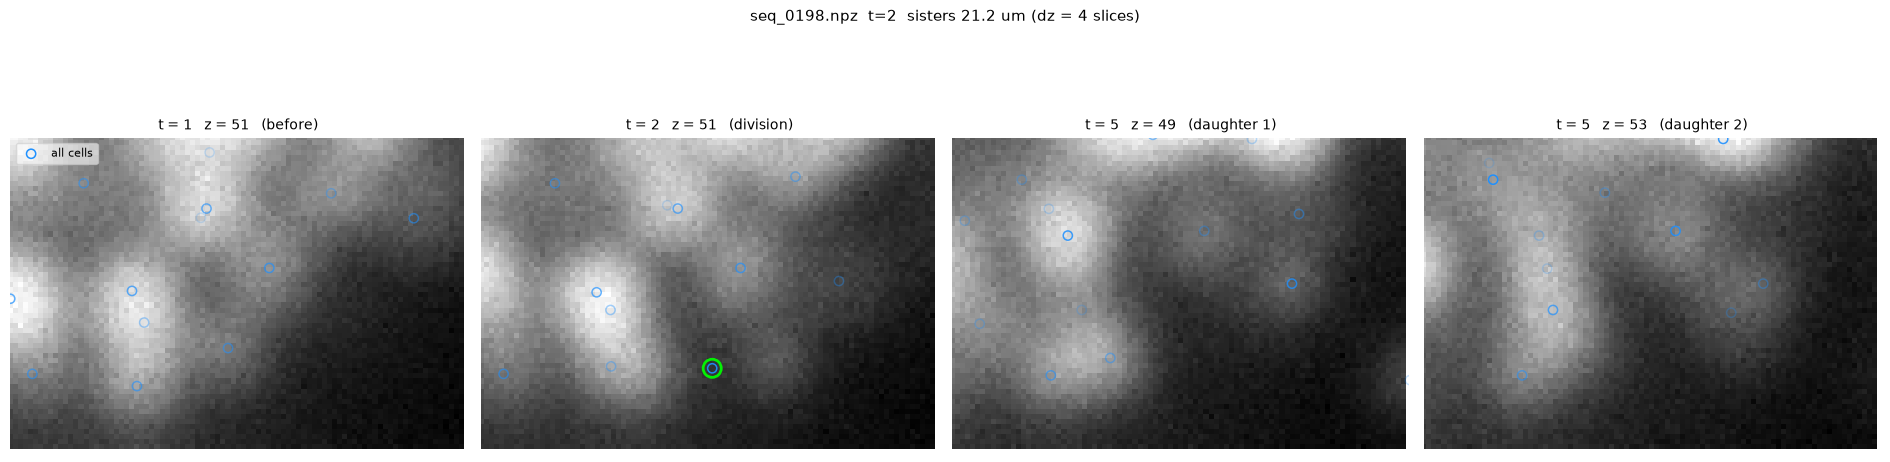

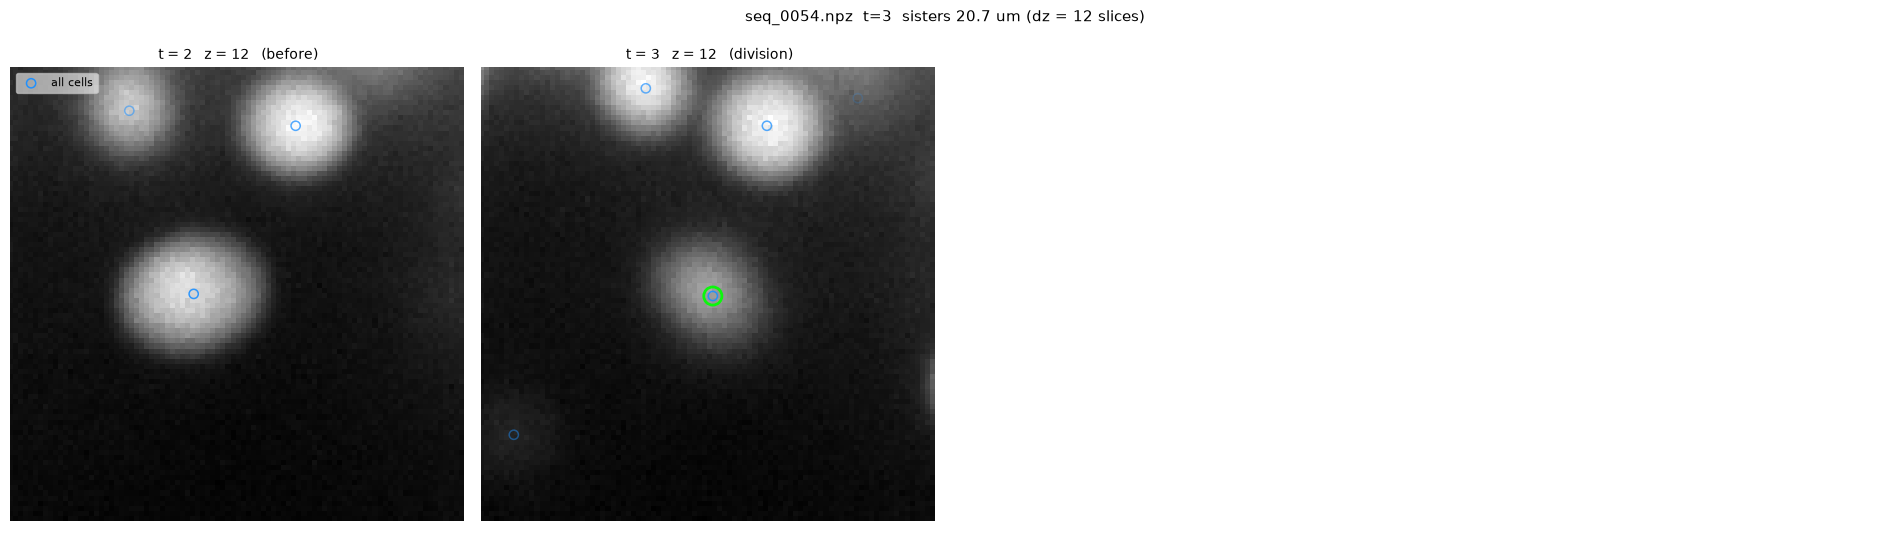

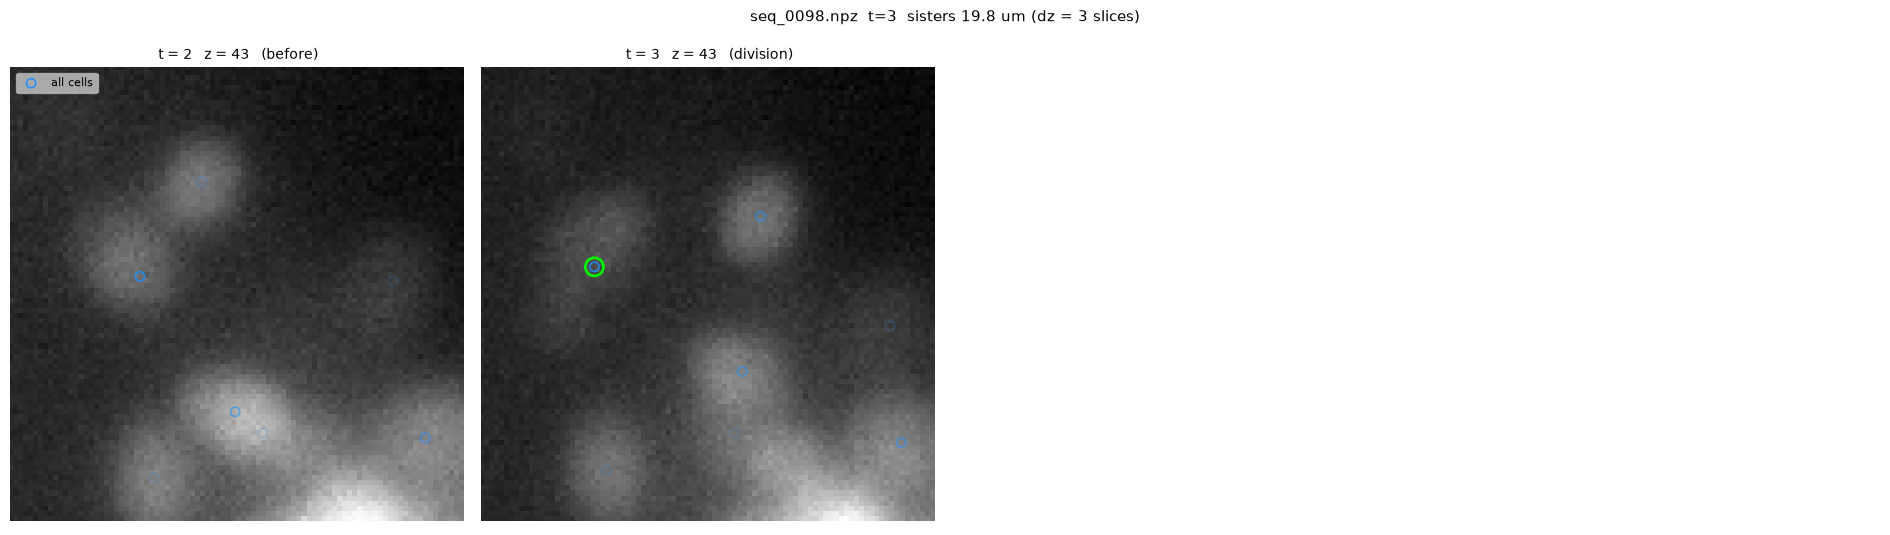

/tmp/ipykernel_700702/786001862.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend(loc="upper left", fontsize=8, framealpha=0.6)


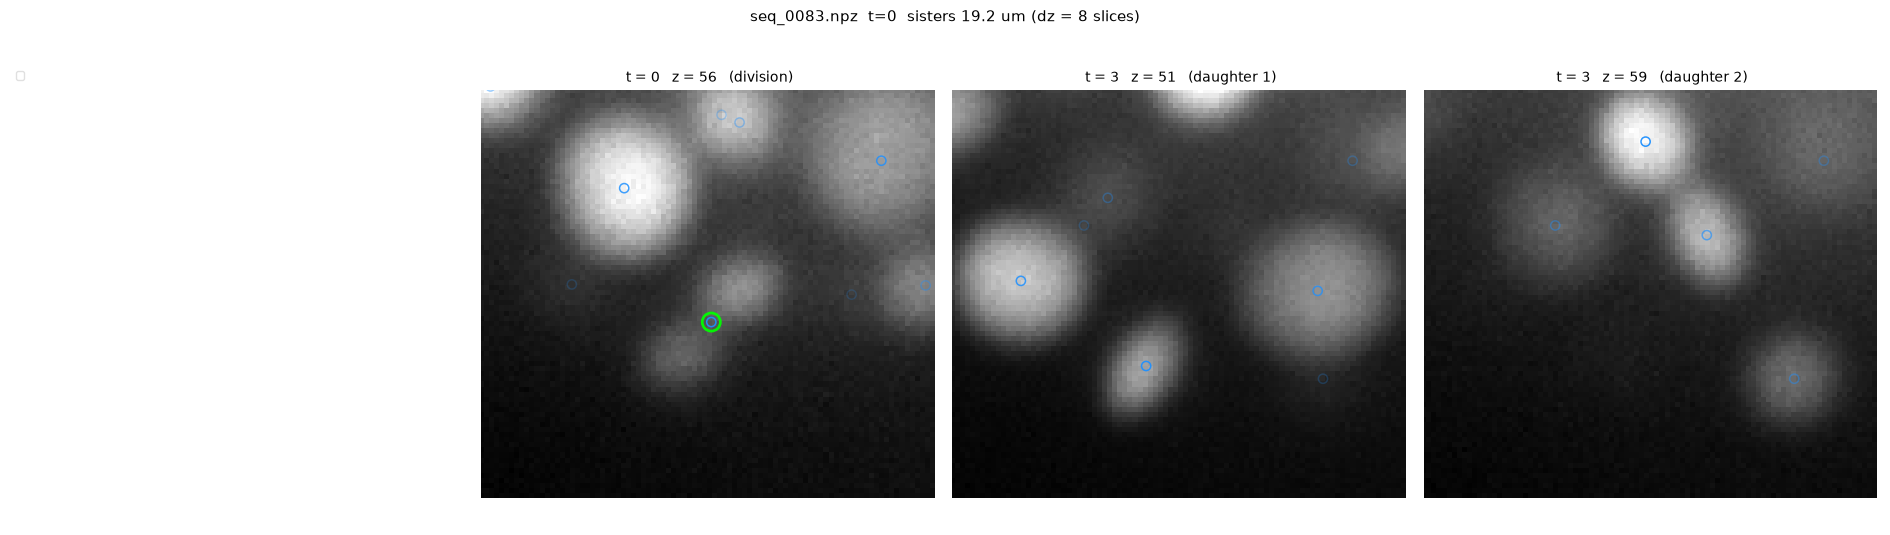

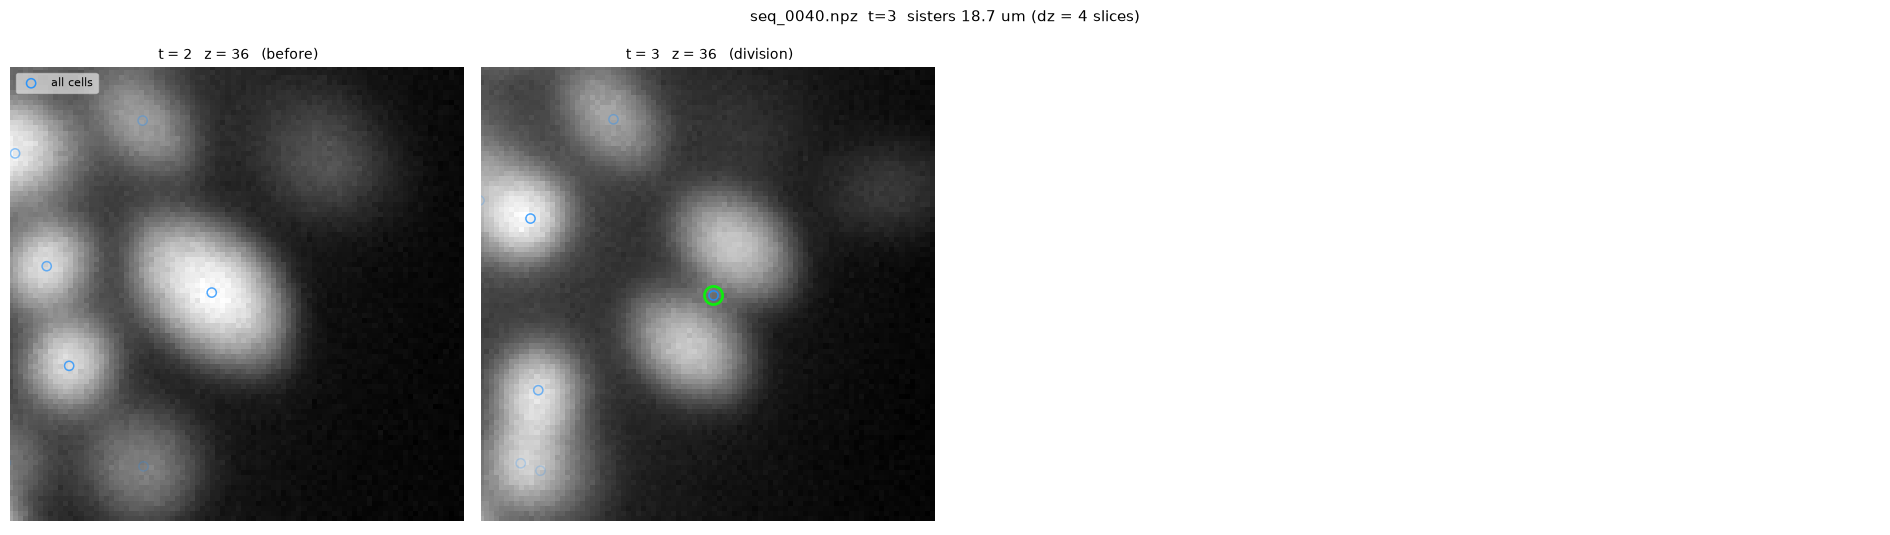

In [63]:
for _, row in synth_div.sort_values("sister_um", ascending=False).head(5).iterrows():
    plot_synth_division(row)

## What the loader actually feeds the model

Everything above shows the generator's own output. Training never sees that: it
sees it after `SyntheticDataset` has normalised, cropped, augmented and — half
the time — mosaicked it. That last step tiles four unrelated windows into one
crop, each with its own orientation and photometry, so the model has to not
hallucinate cells across the seams where they meet.

Two things are worth looking at, and they are different questions. Whether the
images still look like microscopy after the transforms is the first. Whether
the **labels survived** them is the second, and the one that actually breaks
quietly: a coordinate that is not remapped alongside its image is a cell
annotated in the wrong place, which trains the detector against itself and
shows up only as a metric that will not improve.

The config comes from `main_track.DEFAULTS`, not from a copy of it, so this
shows the augmentation the current training run uses rather than what it used
when this cell was written.

In [ ]:
import matplotlib.pyplot as plt

from main_track import DEFAULTS
from tracking.synthetic import SyntheticDataset, find_sequences
from utils.plot import scatter_by_depth

In [ ]:
augs = {
    'crop_anchor_p': 0.9,
    'time_stride_max': 1,
    'flip_p': 0.,
    'rot90_p': 0.,
    'affine_p': 1,
    'rot_z_deg': 0,
    'rot_xy_deg': 0,
    'scale_range': (0.7, 1.45),
    'anisotropic_scale': 0.0,
    'shift_um': 0.0,
    'affine_interpolation': 'bilinear',
    'affine_padding': 'zeros',
    'brightness_p': 0.,
    'brightness_strength': 1.0,
    'blur_p': 0.,
    'blur_sigma_um': 1.0,
    'lowres_p': 0.,
    'lowres_max_factor': 2.0,
    'noise_p': 0.,
    'bg_level_p': 0.,
    'bg_level_range': (0.03, 0.3),
    'dim_p': 0.,
    'dim_factor_range': (0.25, 0.85),
    'dim_min_peak': 0.15,
    'dim_radius_um': (25.0, 70.0)
}

crop_size = DEFAULTS['pretraining']['crop_size']
# crop_size = None
crop_size = (32, 128, 128)

In [19]:


SYNTH = DEFAULTS["synthetic"]
files = find_sequences(OUT)
print(f"{len(files)} sequences  |  window {DEFAULTS['window_size']}  "
      f"|  crop {DEFAULTS['pretraining']['crop_size']}  |  mosaic p={SYNTH['mosaic_p']}")


def loader(augment, mosaic_p):
    """A dataset differing from the training one only in what is switched on."""
    return SyntheticDataset(
        files,
        window_size=DEFAULTS["window_size"],
        max_nodes=int(SYNTH["max_nodes"]),
        crop_size=crop_size,
        augment=augment,
        aug_cfg=augs,
        normalization=DEFAULTS["normalization"],
        mosaic_p=mosaic_p,
        mosaic_jitter=0.1,
    )


def draw(ax, sample, w, z=None, dz=10, title=""):
    """One frame of a window, with the cells within `dz` slices circled.

    Returns the z it drew, so the next frame of the same window can be shown at
    the same depth -- otherwise the two panels are different sections and the
    motion between them is unreadable.
    """
    img = sample["imgs"][w].float().numpy()
    pts = sample["coords"][w][sample["masks"][w]].numpy()
    if z is None:
        z = int(np.median(pts[:, 0])) if len(pts) else img.shape[0] // 2
    z = int(np.clip(z, 0, img.shape[0] - 1))
    ax.imshow(img[z], cmap="gray", vmin=0, vmax=np.percentile(img, 99.5))
    near = scatter_by_depth(ax, pts, z, "lime", tol=dz, s=48, linewidths=0.7)
    ax.set_title(f"{title}  t={w}\nz={z}: {near.sum()} of {len(pts)} cells", fontsize=9)
    # ax.axis("off")
    return z

1000 sequences  |  window 2  |  crop (16, 64, 64)  |  mosaic p=0.0


### One window, transform by transform

Each row adds a stage. Read down a column: the circles have to stay on the
cells at every stage. Read across a row: the same z of the same window one
frame later, which is where the motion shows.

Augmentation resamples the crop under an affine, so a rotated or scaled window
arrives with zero padding at its edges — the dark border is the transform, not
a generation artefact.

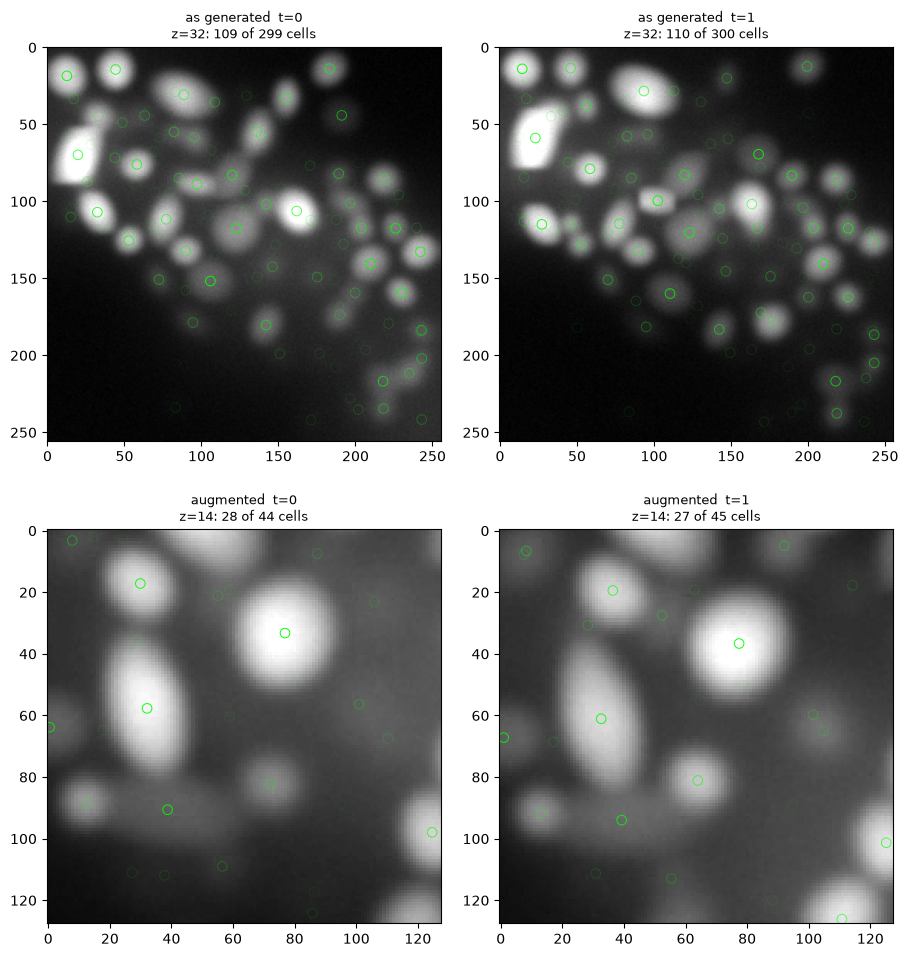

In [20]:
VARIANTS = [
    ("as generated", dict(augment=False, mosaic_p=0.0)),
    ("augmented", dict(augment=True, mosaic_p=0.0)),
    # ("augmented + mosaic", dict(augment=True, mosaic_p=1.0)),
]

rng = np.random.default_rng()
W = DEFAULTS["window_size"]
fig, axes = plt.subplots(len(VARIANTS), W, figsize=(4.6 * W, 4.9 * len(VARIANTS)), squeeze=False)
idx = int(rng.integers(len(files)))

for r, (name, kw) in enumerate(VARIANTS):
    sample = loader(**kw)[idx]
    z = None
    for w in range(min(W, sample["imgs"].shape[0])):
        z = draw(axes[r, w], sample, w, z=z, title=name)
plt.tight_layout()
plt.show()

### Mosaics

Four unrelated windows per crop. The quadrant sizes come from where the mosaic
centre landed, so they differ every draw, and each quarter carries its own
brightness and blur — the seams should be obvious. That is the point: a model
that learns to continue tissue across a discontinuity is a model that
hallucinates.

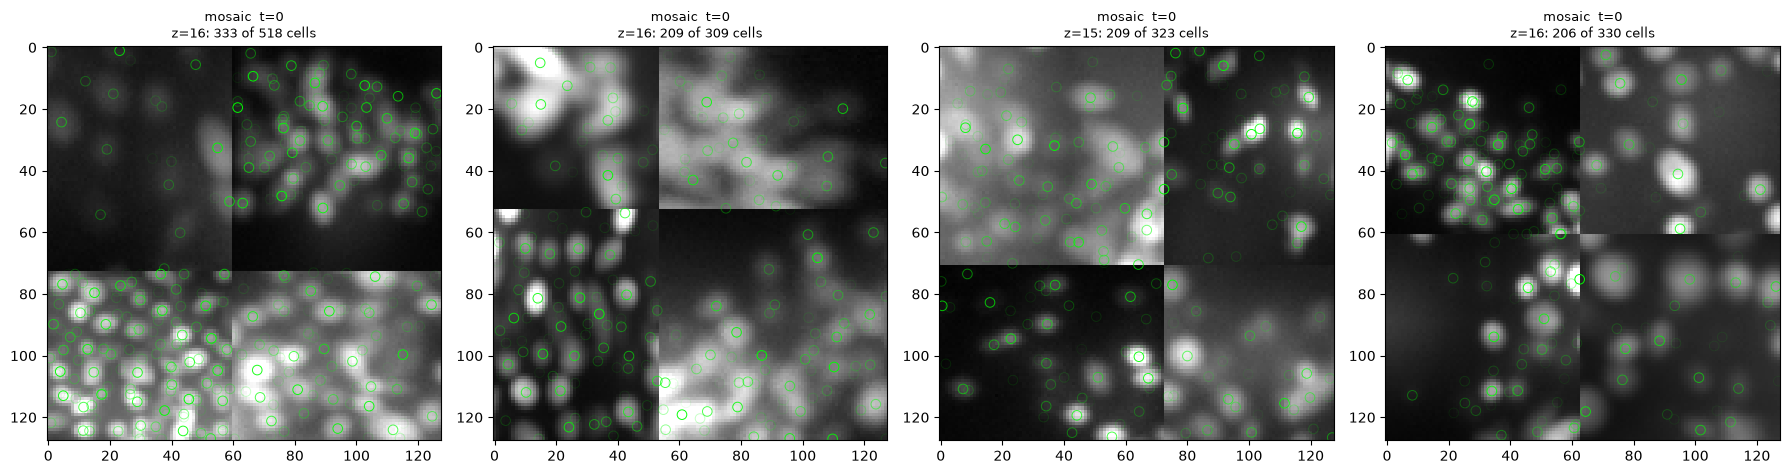

In [21]:
ds = loader(augment=True, mosaic_p=1.0)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax in axes:
    draw(ax, ds[int(rng.integers(len(files)))], 0, title="mosaic")
plt.tight_layout()
plt.show()

### Did the labels survive?

The check the pictures cannot make. Every node must land inside the crop it was
remapped into, and the lineage has to stay a lineage: a cell divides into at
most two, and a cell has exactly one parent. A non-zero count in either of the
last two columns means a transform is moving images and coordinates apart, and
nothing downstream will report it.

In [19]:
N_DRAWS = 12

print(f"{'':22s}{'nodes/frame':>12s}{'edges':>8s}{'out of bounds':>15s}{'bad lineage':>13s}")
for name, kw in VARIANTS:
    ds = loader(**kw)
    n_nodes = n_frames = n_edges = oob = bad = 0
    for _ in range(N_DRAWS):
        s = ds[int(rng.integers(len(files)))]
        extent = np.array(s["imgs"].shape[1:])
        for w in range(s["imgs"].shape[0]):
            pts = s["coords"][w][s["masks"][w]].numpy()
            n_nodes += len(pts)
            n_frames += 1
            if len(pts):
                oob += int(((pts < 0) | (pts >= extent)).any(axis=1).sum())
        tg = s["targets"]
        n_edges += int(tg.sum())
        # a parent links to at most two children, a child to exactly one parent
        bad += int((tg.sum(2) > 2).sum() + (tg.sum(1) > 1).sum())
    print(f"{name:22s}{n_nodes / max(n_frames, 1):12.1f}{n_edges / N_DRAWS:8.1f}"
          f"{oob:15d}{bad:13d}")

                       nodes/frame   edges  out of bounds  bad lineage
as generated                 427.0   437.8              0            0
augmented                     81.8    78.8              0            0


Done !